In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import vitaldb

In [3]:
# Clinical information
cases = pd.read_csv("https://api.vitaldb.net/cases")

# Track list
trks = pd.read_csv("https://api.vitaldb.net/trks")

# Laboratory results
labs = pd.read_csv("https://api.vitaldb.net/labs")

In [4]:
print(cases.shape, trks.shape, labs.shape)

(6388, 74) (486449, 3) (928448, 4)


## Cases

In [5]:
cases.head()

,caseid,subjectid,casestart,caseend,anestart,aneend,opstart,opend,adm,dis,...,intraop_colloid,intraop_ppf,intraop_mdz,intraop_ftn,intraop_rocu,intraop_vecu,intraop_eph,intraop_phe,intraop_epi,intraop_ca
0,1,5955,0,11542,-552,10848.0,1668,10368,-236220,627780,...,0,120,0.0,100,70,0,10,0,0,0
1,2,2487,0,15741,-1039,14921.0,1721,14621,-221160,1506840,...,0,150,0.0,0,100,0,20,0,0,0
2,3,2861,0,4394,-590,4210.0,1090,3010,-218640,40560,...,0,0,0.0,0,50,0,0,0,0,0
3,4,1903,0,20990,-778,20222.0,2522,17822,-201120,576480,...,0,80,0.0,100,100,0,50,0,0,0
4,5,4416,0,21531,-1009,22391.0,2591,20291,-67560,3734040,...,0,0,0.0,0,160,0,10,900,0,2100


In [6]:
cases.columns

Index(['caseid', 'subjectid', 'casestart', 'caseend', 'anestart', 'aneend',
       'opstart', 'opend', 'adm', 'dis', 'icu_days', 'death_inhosp', 'age',
       'sex', 'height', 'weight', 'bmi', 'asa', 'emop', 'department', 'optype',
       'dx', 'opname', 'approach', 'position', 'ane_type', 'preop_htn',
       'preop_dm', 'preop_ecg', 'preop_pft', 'preop_hb', 'preop_plt',
       'preop_pt', 'preop_aptt', 'preop_na', 'preop_k', 'preop_gluc',
       'preop_alb', 'preop_ast', 'preop_alt', 'preop_bun', 'preop_cr',
       'preop_ph', 'preop_hco3', 'preop_be', 'preop_pao2', 'preop_paco2',
       'preop_sao2', 'cormack', 'airway', 'tubesize', 'dltubesize', 'lmasize',
       'iv1', 'iv2', 'aline1', 'aline2', 'cline1', 'cline2', 'intraop_ebl',
       'intraop_uo', 'intraop_rbc', 'intraop_ffp', 'intraop_crystalloid',
       'intraop_colloid', 'intraop_ppf', 'intraop_mdz', 'intraop_ftn',
       'intraop_rocu', 'intraop_vecu', 'intraop_eph', 'intraop_phe',
       'intraop_epi', 'intraop_ca'],
     

In [7]:
for i in cases.columns:
    print(i, cases[i].dtype)

caseid int64
subjectid int64
casestart int64
caseend int64
anestart int64
aneend float64
opstart int64
opend int64
adm int64
dis int64
icu_days int64
death_inhosp int64
age float64
sex str
height float64
weight float64
bmi float64
asa float64
emop int64
department str
optype str
dx str
opname str
approach str
position str
ane_type str
preop_htn int64
preop_dm int64
preop_ecg str
preop_pft str
preop_hb float64
preop_plt float64
preop_pt float64
preop_aptt float64
preop_na float64
preop_k float64
preop_gluc float64
preop_alb float64
preop_ast float64
preop_alt float64
preop_bun float64
preop_cr float64
preop_ph float64
preop_hco3 float64
preop_be float64
preop_pao2 float64
preop_paco2 float64
preop_sao2 float64
cormack str
airway str
tubesize float64
dltubesize str
lmasize float64
iv1 str
iv2 str
aline1 str
aline2 str
cline1 str
cline2 str
intraop_ebl float64
intraop_uo float64
intraop_rbc int64
intraop_ffp int64
intraop_crystalloid float64
intraop_colloid int64
intraop_ppf int64
intraop

In [8]:
# Type d'intervention
cases["optype"].value_counts()

optype
Colorectal          1350
Biliary/Pancreas     812
Others               799
Stomach              676
Major resection      584
Minor resection      553
Breast               434
Transplantation      403
Vascular             262
Hepatic              258
Thyroid              257
Name: count, dtype: int64

In [9]:
# Type d'anesthésie
cases["ane_type"].value_counts()


ane_type
General            6043
Spinal              273
Sedationalgesia      72
Name: count, dtype: int64

In [10]:
cases["age"].describe()

count    6388.000000
mean       57.296493
std        14.976461
min         0.300000
25%        48.000000
50%        59.000000
75%        68.000000
max        94.000000
Name: age, dtype: float64

In [11]:
print("Chirurgies :", cases["caseid"].nunique())
print("Patients   :", cases["subjectid"].nunique())
cases["subjectid"].value_counts().head()

Chirurgies : 6388
Patients   : 6090


subjectid
3131    14
1609    10
4306     8
2291     6
10       5
Name: count, dtype: int64

Plusieurs chirurgies pour un patient

In [12]:
# Durée d'anesthésie
duration = (cases["aneend"] - cases["anestart"]) / 60
duration.describe()

count    6.388000e+03
mean    -9.431647e+03
std      7.697804e+05
min     -6.152447e+07
25%      1.120000e+02
50%      1.750000e+02
75%      2.600000e+02
max      1.860000e+03
dtype: float64

In [13]:
# Le cas aberrant
cases.loc[duration < 0, ["caseid", "anestart", "aneend", "casestart", "caseend"]]

,caseid,anestart,aneend,casestart,caseend
4475,4476,-2156,-3.691470e+09,0,19501


## Liste de features, présente durant la chirurgie
"age", "weight", "bmi", "asa","preop_hb", "preop_alb", "preop_cr", "preop_na", "emop", "preop_htn", "preop_dm", "sex", "department", "optype", "approach", "position"

Les autres features sont hors chirurgie

## Trks

In [25]:
trks.head()

,caseid,tname,tid
0,1,BIS/BIS,fd869e25ba82a66cc95b38ed47110bf4f14bb368
1,1,BIS/EEG1_WAV,0aa685df768489a18a5e9f53af0d83bf60890c73
2,1,BIS/EEG2_WAV,ad13b2c39b19193c8ae4a2de4f8315f18d61a57e
3,1,BIS/EMG,2525603efe18d982764dbca457affe7a45e766a9
4,1,BIS/SEF,1c91aec859304840dec75acf4a35da78be0e8ef0


In [14]:
# PA invasive
art_ids = set(trks.loc[trks["tname"] == "SNUADC/ART", "caseid"])
mbp_ids = set(trks.loc[trks["tname"] == "Solar8000/ART_MBP", "caseid"])
print("SNUADC/ART        :", len(art_ids))
print("Solar8000/ART_MBP :", len(mbp_ids))
print("Les deux          :", len(art_ids & mbp_ids))

SNUADC/ART        : 3645
Solar8000/ART_MBP : 3724
Les deux          : 3644


In [39]:
tid = trks.loc[(trks["caseid"] == 1) & (trks["tname"] == "Solar8000/ART_MBP"), "tid"]
tid

45    5e68ffda69677a28dca49f361e088903239fd1cf
Name: tid, dtype: str

In [40]:
# Echantillonnage brut de la PAM
tid = trks.loc[(trks["caseid"] == 1) & (trks["tname"] == "Solar8000/ART_MBP"), "tid"].iloc[0]
mbp = pd.read_csv(f"https://api.vitaldb.net/{tid}")
mbp.head(20)

,Time,Solar8000/ART_MBP
0,1.818,-8
1,3.817,-8
2,5.818,-8
3,7.817,-9
4,9.817,-9
5,11.816,-8
6,13.816,-8
7,15.815,-9
8,17.815,-9
9,19.814,-9


In [41]:
case = cases.loc[cases["caseid"] == 1].iloc[0]
case

caseid              1
subjectid        5955
casestart           0
caseend         11542
anestart         -552
                ...  
intraop_vecu        0
intraop_eph        10
intraop_phe         0
intraop_epi         0
intraop_ca          0
Name: 0, Length: 74, dtype: object

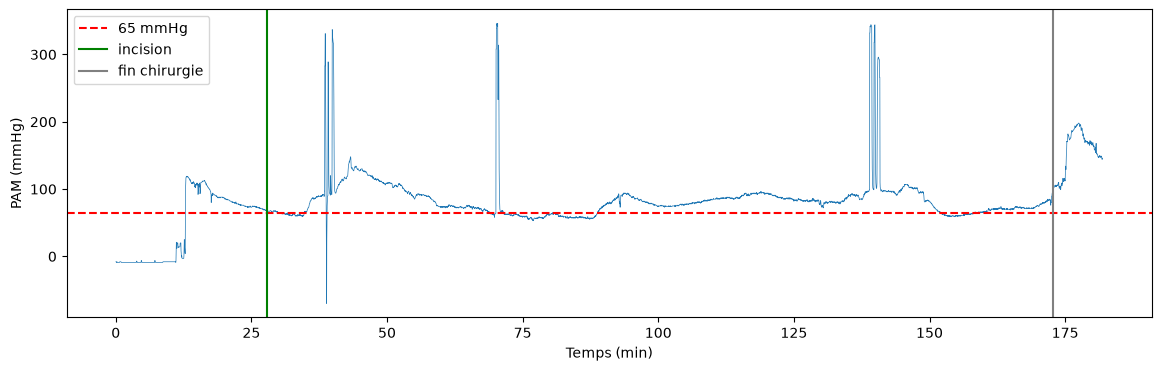

In [42]:
case = cases.loc[cases["caseid"] == 1].iloc[0]

plt.figure(figsize=(14, 4))
plt.plot(mbp["Time"] / 60, mbp["Solar8000/ART_MBP"], lw=0.5)
plt.axhline(65, color="red", ls="--", label="65 mmHg")
plt.axvline(case["opstart"] / 60, color="green", label="incision")
plt.axvline(case["opend"] / 60, color="gray", label="fin chirurgie")
plt.xlabel("Temps (min)")
plt.ylabel("PAM (mmHg)")
plt.legend()
plt.show()

In [43]:
# Liste des signaux enregistrés pour une chirurgie
trks[trks["caseid"] == 1]

,caseid,tname,tid
0,1,BIS/BIS,fd869e25ba82a66cc95b38ed47110bf4f14bb368
1,1,BIS/EEG1_WAV,0aa685df768489a18a5e9f53af0d83bf60890c73
2,1,BIS/EEG2_WAV,ad13b2c39b19193c8ae4a2de4f8315f18d61a57e
3,1,BIS/EMG,2525603efe18d982764dbca457affe7a45e766a9
4,1,BIS/SEF,1c91aec859304840dec75acf4a35da78be0e8ef0
...,...,...,...
71,1,Solar8000/VENT_PPLAT,e1e55590c9da90de55892edf941247b7a6d9213c
72,1,Solar8000/VENT_RR,0b0b820e617889fcc464525f0698fdfc2b3fa79e
73,1,Solar8000/VENT_SET_PCP,e32742aa29d8e4ded02093617f05c1ca72bad344
74,1,Solar8000/VENT_SET_TV,8049dc651b8a55b1c5f0ab17a2e72c1f188b2596


In [44]:
# Signaux les plus fréquents
trks["tname"].value_counts().head(30)

tname
Solar8000/HR             6387
Solar8000/PLETH_HR       6386
Solar8000/PLETH_SPO2     6386
Primus/CO2               6362
Primus/PAMB_MBAR         6361
Primus/SET_AGE           6361
Primus/AWP               6360
SNUADC/ECG_II            6355
Primus/VENT_LEAK         6344
Primus/ETCO2             6339
Primus/FEN2O             6339
Primus/FIN2O             6339
Primus/INCO2             6339
Primus/MAC               6338
Primus/MAWP_MBAR         6338
Primus/FEO2              6335
Primus/FIO2              6335
Primus/RR_CO2            6328
Solar8000/VENT_MAWP      6299
Solar8000/ETCO2          6242
Solar8000/INCO2          6242
Solar8000/FEO2           6239
Solar8000/FIO2           6239
Solar8000/RR_CO2         6177
SNUADC/PLETH             6157
Primus/SET_FIO2          6047
Primus/SET_FRESH_FLOW    6042
Primus/MV                6022
Primus/TV                6018
Primus/COMPLIANCE        6017
Name: count, dtype: int64

In [45]:
labs.head()

,caseid,dt,name,result
0,1,594470,alb,2.9
1,1,399575,alb,3.2
2,1,12614,alb,3.4
3,1,137855,alb,3.6
4,1,399575,alt,12.0


## Téléchargement de 3 signaux du cas 1

Ondes : 1,154,210 points (192.4 min)
PAM   : 11,543 points, 13% de NaN


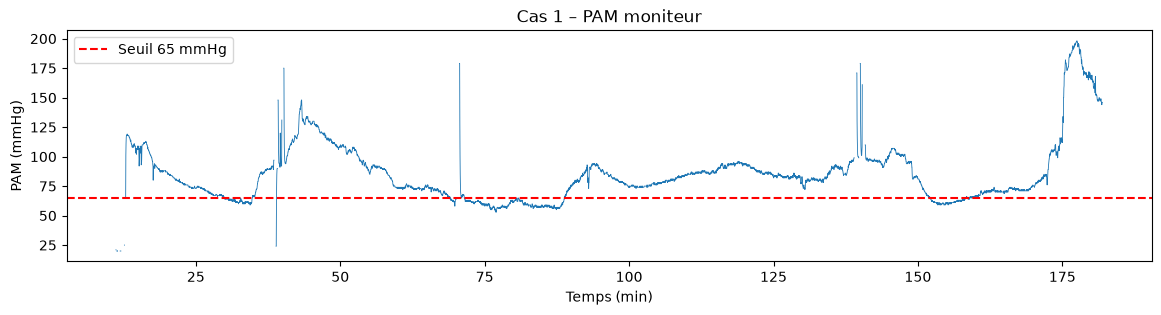

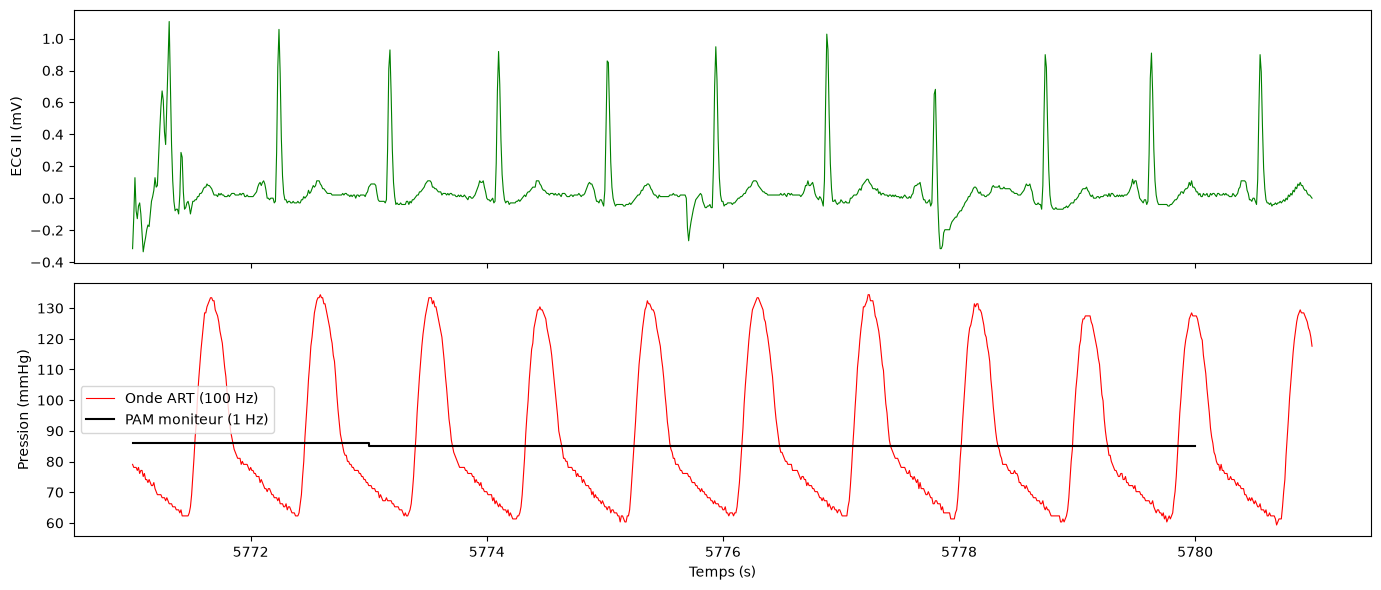

In [46]:
CASE_ID = 1

# --- 1) Ondes à 100 Hz ---
WAVE_TRACKS = ["SNUADC/ART", "SNUADC/ECG_II"]
FS = 100
waves = vitaldb.load_case(CASE_ID, WAVE_TRACKS, 1 / FS)
df_wave = pd.DataFrame(waves, columns=["ART", "ECG_II"])
df_wave["time_s"] = np.arange(len(df_wave)) / FS

# --- 2) PAM du moniteur à 1 Hz ---
num = vitaldb.load_case(CASE_ID, ["Solar8000/ART_MBP"], 1)
df_num = pd.DataFrame(num, columns=["MBP"])
df_num["MBP"] = df_num["MBP"].ffill(limit=4)  # mesure toutes les ~2 s
df_num.loc[(df_num["MBP"] < 20) | (df_num["MBP"] > 200), "MBP"] = np.nan  # artefacts
df_num["time_s"] = np.arange(len(df_num))

print(f"Ondes : {len(df_wave):,} points ({len(df_wave)/FS/60:.1f} min)")
print(f"PAM   : {len(df_num):,} points, {df_num['MBP'].isna().mean():.0%} de NaN")

# --- Vue globale : PAM sur toute la chirurgie ---
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(df_num["time_s"] / 60, df_num["MBP"], lw=0.6)
ax.axhline(65, color="red", ls="--", label="Seuil 65 mmHg")
ax.set(xlabel="Temps (min)", ylabel="PAM (mmHg)", title=f"Cas {CASE_ID} – PAM moniteur")
ax.legend()
plt.show()

# --- Zoom 10 s : onde artérielle vs PAM du moniteur ---
t0 = int(len(df_num) / 2)
w = df_wave[(df_wave["time_s"] >= t0) & (df_wave["time_s"] < t0 + 10)]
n = df_num[(df_num["time_s"] >= t0) & (df_num["time_s"] < t0 + 10)]

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(w["time_s"], w["ECG_II"], color="green", lw=0.8)
axes[0].set_ylabel("ECG II (mV)")
axes[1].plot(w["time_s"], w["ART"], color="red", lw=0.8, label="Onde ART (100 Hz)")
axes[1].step(n["time_s"], n["MBP"], color="black", where="post", label="PAM moniteur (1 Hz)")
axes[1].set_ylabel("Pression (mmHg)")
axes[1].set_xlabel("Temps (s)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [47]:
from pathlib import Path

CASE_ID = 1
out_dir = Path("../data/vital")          # dans data/ -> jamais committé
out_dir.mkdir(parents=True, exist_ok=True)

# Sans track_names : TOUTES les pistes du cas (ondes + constantes + médicaments)
vf = vitaldb.VitalFile(CASE_ID)
print(vf.get_track_names())              # liste des pistes disponibles

out_path = out_dir / f"{CASE_ID}.vital"
vf.to_vital(str(out_path))
print(f"Fichier écrit : {out_path.resolve()} ({out_path.stat().st_size / 1e6:.1f} Mo)")

['EVENT', 'Solar8000/HR', 'Solar8000/ST_I', 'Solar8000/ST_II', 'Solar8000/ST_III', 'Solar8000/ST_AVL', 'Solar8000/ST_AVR', 'Solar8000/ST_AVF', 'Solar8000/ART_MBP', 'Solar8000/ART_SBP', 'Solar8000/ART_DBP', 'Solar8000/PLETH_SPO2', 'Solar8000/PLETH_HR', 'Solar8000/BT', 'Solar8000/VENT_MAWP', 'Solar8000/ST_V5', 'Solar8000/NIBP_MBP', 'Solar8000/NIBP_SBP', 'Solar8000/NIBP_DBP', 'Solar8000/VENT_PIP', 'Solar8000/VENT_RR', 'Solar8000/VENT_MV', 'Solar8000/VENT_TV', 'Solar8000/VENT_PPLAT', 'Solar8000/GAS2_AGENT', 'Solar8000/GAS2_EXPIRED', 'Solar8000/GAS2_INSPIRED', 'Solar8000/ETCO2', 'Solar8000/INCO2', 'Solar8000/RR_CO2', 'Solar8000/FEO2', 'Solar8000/FIO2', 'Solar8000/VENT_INSP_TM', 'Solar8000/VENT_SET_TV', 'Solar8000/VENT_SET_PCP', 'Primus/INSP_SEVO', 'Primus/EXP_SEVO', 'Primus/PAMB_MBAR', 'Primus/MAWP_MBAR', 'Primus/MAC', 'Primus/VENT_LEAK', 'Primus/INCO2', 'Primus/ETCO2', 'Primus/FEO2', 'Primus/FIO2', 'Primus/FIN2O', 'Primus/FEN2O', 'Primus/SET_FIO2', 'Primus/SET_FRESH_FLOW', 'Primus/SET_AGE'